# The Himalayan Database: Exploratory Data Analysis
This notebook provides an initial exploration of the raw Himalayan Database dataset. The focus is on assessing cleanliness, profiling key variablies, and evaluating modeling requirements.

In [1]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_dir = PROJECT_ROOT / "data"

## Peaks
### Description

### Data Types
#### Text
#### Numeric
#### Boolean

### Dependencies
#### peak to location
#### peak to range
#### peak to region
#### location to range
#### location to region
#### range to region

In [3]:
peaks_file_name = data_dir / "peaks.DBF"
df = read_dbf(peaks_file_name)

### Description

In [4]:
df.head()

,peakid,pkname,pkname2,location,heightm,heightf,himal,region,open,unlisted,...,peakmemo,pyear,pseason,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,6814,22356,12,2,True,False,...,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,1,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),5630,18471,12,2,True,False,...,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,1,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,8091,26545,1,5,True,False,...,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,1,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,NaN,Annapurna Himal,7937,26040,1,5,True,False,...,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,1,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,NaN,Annapurna Himal,7555,24787,1,5,True,False,...,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,1,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [5]:
df.shape

(503, 25)

In [6]:
pd.DataFrame({
  "column_name": df.columns,
  "data_type": [df[col].dtype for col in df.columns],
  "nan_count": [df[col].isna().sum() for col in df.columns],
  "nan_perc": [df[col].isna().sum() / len(df[col]) for col in df.columns],
  "unique_values": [df[col].nunique() for col in df.columns]
})

,column_name,data_type,nan_count,nan_perc,unique_values
0,peakid,str,0,0.000000,503
1,pkname,str,0,0.000000,503
2,pkname2,str,244,0.485089,256
3,location,str,1,0.001988,421
4,heightm,int64,0,0.000000,433
5,heightf,int64,0,0.000000,433
6,himal,int64,0,0.000000,20
7,region,int64,0,0.000000,7
8,open,bool,0,0.000000,2
9,unlisted,bool,0,0.000000,2


In [7]:
df.select_dtypes(include=[str]).head(5)

,peakid,pkname,pkname2,location,trekyear,restrict,peakmemo,pyear,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,NaN,NaN,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),NaN,Opened in 2002,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [8]:
assert df.peakid.notna().all()
assert df.peakid.is_unique

The __peakid__ presents as a valid primary key for the peaks dataset (unique, no missing values)

### Distributions

In [9]:
# verify imperial to metric conversion
assert ((df.heightf / df.heightm).max() - (df.heightf / df.heightm).min()) < .001

In [10]:
df.heightm.describe()

count     503.000000
mean     6633.912525
std       566.623177
min      5407.000000
25%      6225.500000
50%      6530.000000
75%      6874.500000
max      8849.000000
Name: heightm, dtype: float64

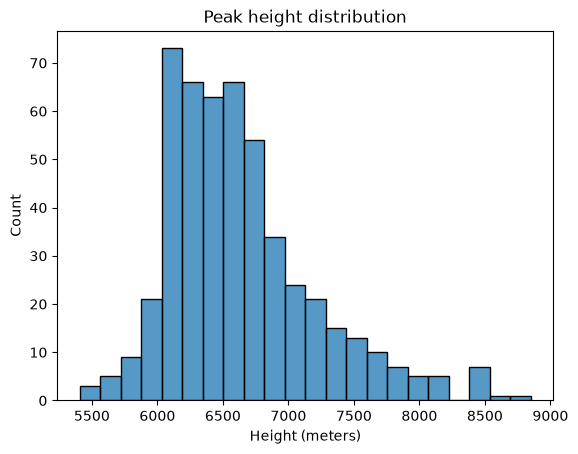

In [11]:
sns.histplot(data=df, x="heightm")
plt.title("Peak height distribution")
plt.xlabel("Height (meters)")
plt.show()

In [12]:
df.trekking.value_counts(dropna=False, normalize=True)

trekking
False    0.934394
True     0.065606
Name: proportion, dtype: float64

In [13]:
df.pstatus.value_counts(dropna=False, normalize=True)

pstatus
2    0.767396
1    0.232604
Name: proportion, dtype: float64

In [14]:
df.open.value_counts(dropna=False, normalize=True)

open
True     0.805169
False    0.194831
Name: proportion, dtype: float64

In [15]:
df.unlisted.value_counts(dropna=False, normalize=True)

unlisted
False    0.872763
True     0.127237
Name: proportion, dtype: float64

### Relationships
#### __peak to location__

In [16]:
print("Most peaks in one location:", df.groupby('location')['peakid'].nunique().max())
print("Most locations associated with one peak:", df.groupby('peakid')['location'].nunique().max())

Most peaks in one location: 6
Most locations associated with one peak: 1


#### __peak to range__

In [17]:
print("Most peaks in one range:", df.groupby('himal')['peakid'].nunique().max())
print("Most ranges associated with one peak:", df.groupby('peakid')['himal'].nunique().max())

Most peaks in one range: 79
Most ranges associated with one peak: 1


#### __peak to region__

In [18]:
print("Most peaks in one region:", df.groupby('region')['peakid'].nunique().max())
print("Most regions associated with one peak:", df.groupby('peakid')['region'].nunique().max())

Most peaks in one region: 137
Most regions associated with one peak: 1


#### __location to range__

In [19]:
print("Most locations in one range:", df.groupby('himal')['location'].nunique().max())
print("Most ranges associated with one location:", df.groupby('location')['himal'].nunique().max())

Most locations in one range: 64
Most ranges associated with one location: 1


#### __location to region__

In [20]:
print("Most locations in one region:", df.groupby('region')['location'].nunique().max())
print("Most regions associated with one location:", df.groupby('location')['region'].nunique().max())

Most locations in one region: 113
Most regions associated with one location: 1


#### __range to region__

In [21]:
print("Most ranges in one region:", df.groupby('region')['himal'].nunique().max())
print("Most regions associated with one range:", df.groupby('himal')['region'].nunique().max())

Most ranges in one region: 5
Most regions associated with one range: 2


In [22]:
df.loc[df.location.isna()]

,peakid,pkname,pkname2,location,heightm,heightf,himal,region,open,unlisted,...,peakmemo,pyear,pseason,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
461,SANK,Sano Kailash,NaN,NaN,6452,21168,3,5,False,True,...,Other map altitudes:\r\n 6425m - Nepa\r\n ...,2019,1,SANK19101,Apr 28,"Austria, Nepal","Wolfgang Drexler, Lawang Tamang",NaN,NaN,NaN


- transitive relationships through nested geographical data: range > location > peak
- one peak has missing location entry
- many-to-many relationship between range and region

__Peaks Table profile__

| Column    | DATA TYPE | VARIABLE TYPE | KEY |
| -------- | ------- | ------- | ------- |
| peakid  | TEXT    | FIXED | PK |
| name | TEXT     | FIXED ||
| location | INT | FIXED | FK |
| height | INT | FIXED ||
| himal | INT | FIXED | FK |
| region | INT | FIXED | FK |
| open | BOOLEAN | SCD ||
| unlisted | BOOLEAN | SCD ||
| trekking | BOOLEAN | SCD ||
| trekking_since | INT | SCD ||
| restrict | TEXT | SCD ||
| host | TEXT | FIXED | FK |
| status | TEXT | SCD ||
| refermemo | TEXT | SCD ||
| photomemo | TEXT | SCD ||

Dimensional tables:
- Ranges
- Region
- Country


In [23]:
for col in df.columns:
  print(col)

peakid
pkname
pkname2
location
heightm
heightf
himal
region
open
unlisted
trekking
trekyear
restrict
phost
pstatus
peakmemo
pyear
pseason
pexpid
psmtdate
pcountry
psummiters
psmtnote
refermemo
photomemo


## Expeditions

In [24]:
exped_file_name = data_dir / "exped.DBF"
df = read_dbf(exped_file_name)

In [25]:
df.shape

(11854, 66)

In [26]:
df.head()

,expid,peakid,year,season,host,route1,route2,route3,route4,nation,...,accidents,achievment,agency,comrte,stdrte,primrte,primmem,primref,primid,chksum
0,ANN260101,ANN2,1960,1,1,NW Ridge-W Ridge,NaN,NaN,NaN,UK,...,NaN,NaN,NaN,None,None,False,False,None,NaN,2442047
1,ANN269301,ANN2,1969,3,1,NW Ridge-W Ridge,NaN,NaN,NaN,Yugoslavia,...,Draslar frostbitten hands and feet,NaN,NaN,None,None,False,False,None,NaN,2445501
2,ANN273101,ANN2,1973,1,1,W Ridge-N Face,NaN,NaN,NaN,Japan,...,NaN,NaN,NaN,None,None,False,False,None,NaN,2446797
3,ANN278301,ANN2,1978,3,1,N Face-W Ridge,NaN,NaN,NaN,UK,...,NaN,NaN,NaN,None,None,False,False,None,NaN,2448822
4,ANN279301,ANN2,1979,3,1,N Face-W Ridge,NW Ridge of A-IV,NaN,NaN,UK,...,NaN,NaN,NaN,None,None,False,False,None,NaN,2449204


In [27]:
df[['expid', 'peakid', 'year', 'season']].head()

,expid,peakid,year,season
0,ANN260101,ANN2,1960,1
1,ANN269301,ANN2,1969,3
2,ANN273101,ANN2,1973,1
3,ANN278301,ANN2,1978,3
4,ANN279301,ANN2,1979,3


Expedition ID are built concatenations of:
- __peak ID__ (e.g: ANN2)
- last 2 digits of __expedition year__ (e.g: 60)
- __expedition season__ (e.g: 1)
- __expedition number__ (e.g: 01)

This construct is susceptible to conflict in the (infrequent but plausible) event of two expeditions to the same peak in the same season taking place one century appart. Uniqueness is easily ensured by appending the full year to the ID values.

In [28]:
assert df.expid.is_unique
assert df.expid.notna().all()

AssertionError: 

In [29]:
df.expid = df.expid.str.cat(df.year, "_")

In [30]:
assert df.expid.is_unique
assert df.expid.notna().all()

In [31]:
df.route1 = df.route1.str.lower()

In [32]:
df.route1.nunique() / df.shape[0]

0.108149147966931

In [70]:
(df.route1.value_counts() == 1).mean()

np.float64(0.7683307332293292)

In [33]:
df.route1.value_counts()[:10]

route1
sw ridge              1786
s col-se ridge        1354
nw side               1109
ne face                876
n col-ne ridge         791
w face                 470
ne ridge               455
se ridge               432
makalu la-nw ridge     295
nw ridge               290
Name: count, dtype: int64

In [34]:
df.route1.value_counts()[-10:]

route1
s pillar (to 6000m)                        1
w face-sw ridge (up), e ridge (down)       1
w face (variant)                           1
e ridge (from chu2), s ridge (down)        1
se face (up), w ridge (to chu1)            1
se face (from jyal), sw ridge (to kek1)    1
ne ridge (from jyal), se face (down)       1
ene ridge                                  1
e face-se ridge (up), s face (down)        1
ne side?                                   1
Name: count, dtype: int64

In [72]:
route_counts = df.groupby(['peakid', 'route1'], as_index=False)['expid'].count()
print("Number of peakid/route combinations:", route_counts.shape[0])
print("Percentage of repeated combinations:", 100 * (route_counts.expid > 1).mean())

Number of peakid/route combinations: 2422
Percentage of repeated combinations: 21.26341866226259


In [62]:
route_counts.expid.describe()

count    2422.000000
mean        4.818745
std        54.681094
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max      1583.000000
Name: expid, dtype: float64

In [67]:
peak_routes = df.groupby('peakid', as_index=False).agg(
  expedition_count=pd.NamedAgg(column="expid", aggfunc="nunique"),
  route_count=pd.NamedAgg(column="route1", aggfunc="nunique"),
)
peak_routes["ratio"] = peak_routes.expedition_count / peak_routes.route_count

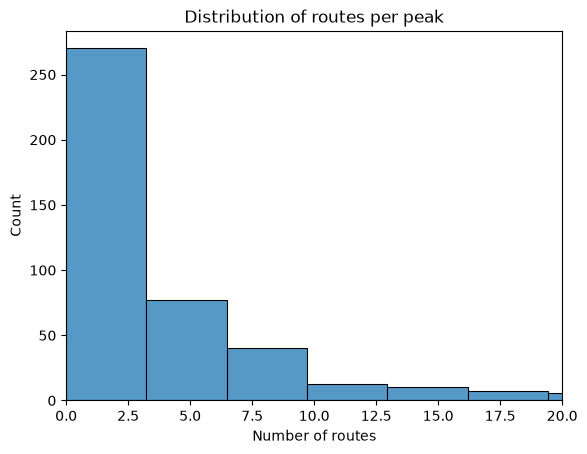

In [68]:
sns.histplot(data=peak_routes, x="route_count")
plt.title("Distribution of routes per peak")
plt.xlabel("Number of routes")
plt.xlim((0, 20))
plt.show()

In [37]:
peak_routes.route_count.describe()

count    439.000000
mean       5.517084
std       10.916204
min        0.000000
25%        1.000000
50%        2.000000
75%        5.500000
max      136.000000
Name: route_count, dtype: float64

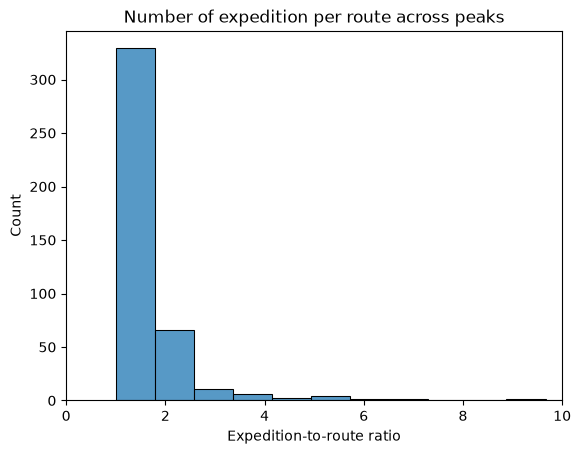

In [38]:
sns.histplot(data=peak_routes.loc[peak_routes.route_count > 0], x="ratio")
plt.title("Number of expedition per route across peaks")
plt.xlabel("Expedition-to-route ratio")
plt.xlim((0, 10))
plt.show()

In [39]:
peak_routes.loc[peak_routes.route_count > 0].ratio.describe()

count    428.000000
mean       1.773039
std        2.543009
min        1.000000
25%        1.000000
50%        1.200000
75%        1.666667
max       34.081633
Name: ratio, dtype: float64

The route variables in the expeditions dataset (route1, route2, route3, route4) are free-from, unstructured names given to the path followed by an expedition. Entries range from short, oft-repeated entries (e.g: SW Ridge, W Face) to unique idiosyncratic descriptions (e.g: _se face (from jyal), sw ridge (to kek1)_)

Notes:
- there are 2422 peak ID/route combinations in the dataset (approximately 80% are unique)
- on average, a single peak route has been taken by 1.7 expeditions

Despite the high prevalence of unique routes, there is a substantial subset of frequently recurring peak routes